# Building age classification: Madrid to Amsterdam transfer

This notebook runs the whole pipeline end to end with a fixed random seed:

1. Build one feature row per pixel for both cities.
2. Stage 1: cross-validate and train the year-bin model on Madrid only.
3. Zero-shot check: the Madrid model applied to Amsterdam with no Amsterdam labels.
4. Stage 2: adapt to Amsterdam with `N_PER_CLASS` labelled pixels per class.
5. Results for all five sample sizes, with error bars.

The functions live in `bac.py` in this folder. Set the parameters in the next cell, then use Run All.

In [2]:
# Parameters: change these, then Run All
N_PER_CLASS = 25            # labelled Amsterdam pixels per class: 5, 25, 50, 100 or 200
SEED = 42                   # fixed seed for the labelled sample, the folds and the models
DATA_DIR = '../data'        # folder holding madrid_train.parquet and amsterdam_data.parquet
OUT_DIR = 'outputs'         # models, cached features and results
N_JOBS = 6                  # CPU threads; keep modest on a shared server
STAGE1_TREES, STAGE1_LR = 150, 0.1   # boosting settings used for the reported results
RETRAIN_STAGE1 = False      # True: rerun Madrid cross-validation and retrain Stage 1 (about 10 minutes)
RUN_FULL_SWEEP = False      # True: rerun every method at every n over N_TRIALS draws (about 15 minutes)
N_TRIALS = 30

In [3]:
import json
import subprocess
import sys
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import RepeatedStratifiedKFold

import bac

warnings.filterwarnings('ignore', category=UserWarning)
bac.N_JOBS = N_JOBS
bac.N_TREES, bac.LEARNING_RATE = STAGE1_TREES, STAGE1_LR
out = Path(OUT_DIR)
out.mkdir(exist_ok=True)
MADRID_FILE = f'{DATA_DIR}/madrid_train.parquet'
AMSTERDAM_FILE = f'{DATA_DIR}/amsterdam_data.parquet'
CLASS_NAMES = ['1: pre-1960', '2: 1960-1984', '3: 1984-2004', '4: 2004-2024']   # Madrid boundaries

## 1. Features

One row per pixel. For each of the six bands and five indices: overall and per-decade levels, year-to-year change, the year and size of the largest jump and of the best step change, and the trend. Neighbourhood averages over nearby building pixels, building density, coverage and relative distance to the urban core are added; they use neighbours' spectra only, never their labels. Features are built once and cached in `OUT_DIR`.

In [4]:
def city_features(name, path):
    cache = out / f'features_{name}.parquet'
    if cache.exists():
        return pd.read_parquet(cache)
    df = bac.build_features([path])
    df.to_parquet(cache)
    return df


madrid = city_features('madrid', MADRID_FILE)
amsterdam = city_features('amsterdam', AMSTERDAM_FILE)
madrid = madrid[madrid['age_class'].notna()].reset_index(drop=True)
amsterdam = amsterdam[amsterdam['age_class'].notna()].reset_index(drop=True)
FEATURES = bac.feature_columns(madrid)
CITY = amsterdam['city'].iloc[0]
print(f'Madrid: {len(madrid):,} pixels | Amsterdam: {len(amsterdam):,} pixels | {len(FEATURES)} features')
counts = pd.DataFrame({'Madrid': madrid['age_class'].astype(int).value_counts().sort_index(),
                       'Amsterdam': amsterdam['age_class'].astype(int).value_counts().sort_index()})
counts.rename_axis('class')

Madrid: 76,263 pixels | Amsterdam: 25,992 pixels | 393 features


,Madrid,Amsterdam
class,,
1,13794,7568
2,27152,8802
3,18672,6745
4,16645,2877


## 2. Stage 1: Madrid model

LightGBM predicts ten construction-year bins with balanced weights. Every class boundary of both cities is a bin edge, so each city's four classes are exact sums of bins, despite the different 1960 (Madrid) and 1945 (Amsterdam) boundaries. Trained on Madrid only. With `RETRAIN_STAGE1 = False` the saved model and cross-validation results are loaded.

In [5]:
model_path = out / 'stage1_model.joblib'
if RETRAIN_STAGE1 or not model_path.exists():
    X = madrid[FEATURES].fillna(madrid[FEATURES].median()).to_numpy(np.float32)
    y = madrid['age_class'].to_numpy(int)
    year = madrid['weighted_mean_year'].to_numpy()
    scores, cm = [], np.zeros((4, 4))
    folds = RepeatedStratifiedKFold(n_splits=5, n_repeats=1, random_state=SEED)
    for i, (tr, va) in enumerate(folds.split(X, y), 1):
        fold_model = bac.fit_bins(X[tr], year[tr], SEED)
        pred = bac.bins_to_class_proba(bac.predict_bins(fold_model, X[va]), 'Madrid').argmax(axis=1) + 1
        scores.append(f1_score(y[va], pred, average='macro'))
        cm += confusion_matrix(y[va], pred, labels=[1, 2, 3, 4])
        print(f'fold {i}/5: macro F1 = {scores[-1]:.4f}')
    json.dump({'macro_f1_mean': float(np.mean(scores)), 'macro_f1_std': float(np.std(scores)),
               'scores': [float(s) for s in scores], 'folds': 5, 'repeats': 1,
               'confusion_matrix_proportions': (cm / cm.sum(axis=1, keepdims=True)).tolist(),
               'n_features': len(FEATURES)}, open(out / 'madrid_cv.json', 'w'), indent=2)
    bundle = bac.make_bundle(madrid, SEED)
    bundle['city_year_norm'] = False
    joblib.dump(bundle, model_path, compress=3)

bundle = joblib.load(model_path)
cv = json.load(open(out / 'madrid_cv.json'))
print(f"Madrid 5-fold cross-validation macro F1: {cv['macro_f1_mean']:.3f} +/- {cv['macro_f1_std']:.3f}")
print('Confusion matrix proportions (rows: actual class, columns: predicted class):')
pd.DataFrame(cv['confusion_matrix_proportions'], index=CLASS_NAMES, columns=CLASS_NAMES).round(3)

Madrid 5-fold cross-validation macro F1: 0.750 +/- 0.005
Confusion matrix proportions (rows: actual class, columns: predicted class):


,1: pre-1960,2: 1960-1984,3: 1984-2004,4: 2004-2024
1: pre-1960,0.691,0.254,0.038,0.017
2: 1960-1984,0.117,0.780,0.082,0.022
3: 1984-2004,0.038,0.170,0.741,0.052
4: 2004-2024,0.020,0.083,0.130,0.766


## 3. Zero-shot transfer

The Madrid model applied to every Amsterdam pixel with no Amsterdam labels, its year bins regrouped at Amsterdam's class boundaries.

In [6]:
X_ams = bac.matrix(bundle, amsterdam)
y_ams = amsterdam['age_class'].to_numpy(int)
zero = bac.zero_shot(bundle, X_ams, CITY)
print(f'Zero-shot macro F1 (no {CITY} labels): {f1_score(y_ams, zero, average="macro"):.4f}')

Zero-shot macro F1 (no Amsterdam labels): 0.4495


## 4. Stage 2: adapt to Amsterdam with `N_PER_CLASS` labels per class

`N_PER_CLASS` pixels per class are drawn at random with `SEED`, and every other Amsterdam pixel is used for scoring. The method for each n is the one that scored best over 30 draws, read from `best_per_n.json`:

- `stack_et`: extra-trees on the features plus the Stage 1 year-bin log-probabilities.
- `blend`: average of `stack_et` and a regularised logistic regression on the Stage 1 outputs.
- `align`: first remove a class-by-class estimate of the feature offset between the cities, from the labelled pixels only.

A single draw is noisier than the 30-draw mean in section 5.

In [7]:
best_path = out / 'best_per_n.json'
choice = json.load(open(best_path)) if best_path.exists() else {}
if str(N_PER_CLASS) in choice:
    method, align = choice[str(N_PER_CLASS)]['method'], choice[str(N_PER_CLASS)]['align']
else:
    method, align = 'stack_et', False

rng = np.random.default_rng(SEED)
support = bac.sample_support(y_ams, N_PER_CLASS, rng)
query = np.setdiff1d(np.arange(len(y_ams)), support)
stage2 = bac.Stage2(bundle, CITY, method, align, SEED).fit(X_ams[support], y_ams[support])
pred = stage2.predict(X_ams[query])

print(f'n = {N_PER_CLASS} per class ({len(support)} labelled pixels), method = {method}, align = {align}')
print(f'Macro F1 on the other {len(query):,} pixels: {f1_score(y_ams[query], pred, average="macro"):.4f}')
print(classification_report(y_ams[query], pred, digits=3))

amsterdam.loc[query, ['px_key', 'py_key']].assign(predicted_class=pred).to_csv(
    out / f'predictions_n{N_PER_CLASS}.csv', index=False)
_ = joblib.dump({'stage2': stage2, 'support_pixels': amsterdam.loc[support, ['px_key', 'py_key']],
                 'n': N_PER_CLASS, 'seed': SEED}, out / f'stage2_model_n{N_PER_CLASS}.joblib', compress=3)

n = 25 per class (100 labelled pixels), method = stack_et, align = False
Macro F1 on the other 25,892 pixels: 0.6750
              precision    recall  f1-score   support

           1      0.735     0.702     0.718      7543
           2      0.668     0.588     0.626      8777
           3      0.678     0.699     0.688      6720
           4      0.571     0.806     0.668      2852

    accuracy                          0.674     25892
   macro avg      0.663     0.699     0.675     25892
weighted avg      0.679     0.674     0.673     25892



## 5. All sample sizes over repeated draws

With `RUN_FULL_SWEEP = True` this reruns `evaluate_fewshot.py`, which tries every method at n = 5, 25, 50, 100 and 200 over `N_TRIALS` random draws, picks the best per n, and writes the table and plot. Otherwise the saved results are shown. "Provided baseline" is the organisers' figure from Notebook 4.

In [8]:
if RUN_FULL_SWEEP:
    subprocess.run([sys.executable, 'evaluate_fewshot.py', '--amsterdam', AMSTERDAM_FILE, '--out', OUT_DIR,
                    '--trials', str(N_TRIALS), '--seed', str(SEED)], check=True)

results = pd.read_csv(out / 'fewshot_results.csv')
best = json.load(open(out / 'best_per_n.json'))
provided = {5: 0.544, 25: 0.599, 50: 0.608, 100: 0.613, 200: 0.615}
rows = []
for n, base in provided.items():
    b = best[str(n)]
    ours = results[(results['n'] == n) & (results['method'] == b['method']) & (results['align'] == b['align'])].iloc[0]
    proto = results[(results['n'] == n) & (results['method'] == 'prototype')].iloc[0]
    rows.append({'n per class': n, 'ours mean': ours['mean'], 'ours std': ours['std'],
                 'prototypes on our features': proto['mean'], 'provided baseline': base,
                 'gain': ours['mean'] - base, 'method': b['method'] + (' + align' if b['align'] else '')})
summary = pd.DataFrame(rows)
print(f"Average of the five: ours {summary['ours mean'].mean():.3f}, provided baseline {np.mean(list(provided.values())):.3f}")
summary.round(3)

Average of the five: ours 0.697, provided baseline 0.596


,n per class,ours mean,ours std,prototypes on our features,provided baseline,gain,method
0,5,0.601,0.040,0.556,0.544,0.057,blend + align
1,25,0.689,0.019,0.601,0.599,0.090,stack_et
2,50,0.710,0.013,0.618,0.608,0.102,stack_et + align
3,100,0.733,0.009,0.619,0.613,0.120,stack_et
4,200,0.752,0.005,0.622,0.615,0.137,stack_et


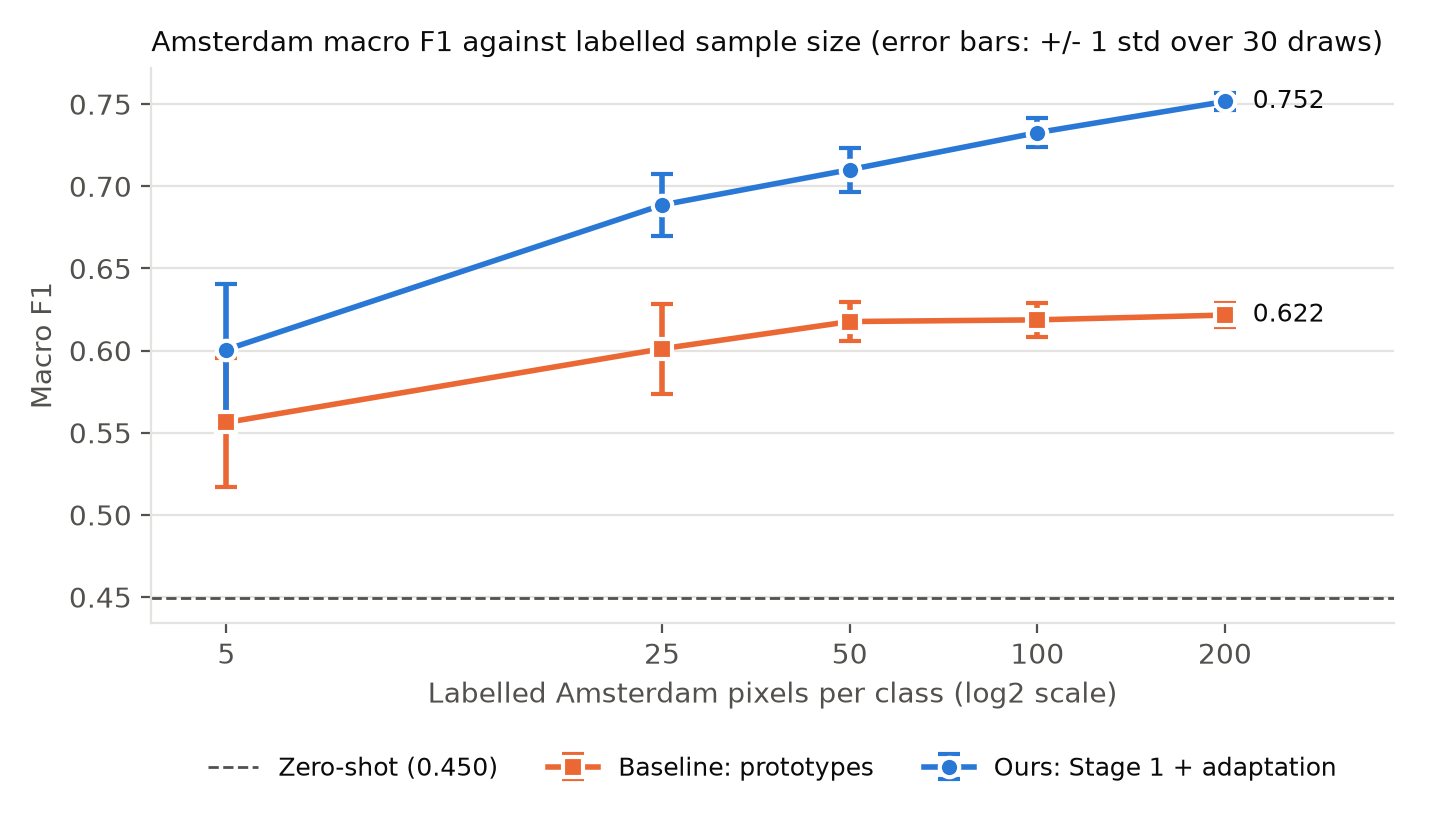

In [9]:
display(Image(filename=str(out / 'f1_vs_log2n.png'), width=760))